In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [2]:
data = pd.read_csv('datasets/MNIST_digit_train.csv')
data_test = pd.read_csv('datasets/MNIST_digits_test.csv')

In [3]:
data.head()


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
data = np.array(data)
m,n = data.shape
# Conjunto de validación
data_dev = data[0:1000].T
Y_dev = data_dev[0]
X_dev = data_dev[1:n] / 255.  # Divide by 255. to normalize

# Conjunto de entrenamiento
data_train = data[1000:m].T
Y_train = data_train[0]
X_train = data_train[1:n] / 255.  

In [5]:
data_test = np.array(data_test).T
m,n = data.shape
X_test = data_test / 255.

In [6]:
def init_params():
    W1 = np.random.rand(10, 784) - 0.5  
    b1 = np.random.rand(10, 1) - 0.5
    W2 = np.random.rand(10, 10) - 0.5
    b2 = np.random.rand(10, 1) - 0.5
    
    return b1,b2,W1,W2

def ReLU(Z1):
    return np.maximum(0,Z1)

def softmax(Z2):
    # Calculate max and sum along axis=0 (per column/image)
    shifted_Z2 = Z2 - np.max(Z2, axis=0, keepdims=True)
    exps = np.exp(shifted_Z2)
    return exps / np.sum(exps, axis=0, keepdims=True)

def forward_prop(W1,b1,W2,b2,X):
    Z1 = W1.dot(X) + b1
    A1 =ReLU(Z1)
    Z2 = W2.dot(A1) + b2
    A2 = softmax(Z2)
    return Z1,A1,Z2,A2

def one_hot(Y):
    # size = m, and Y.max()+1 means our possible digits 0..9
    res = np.zeros((Y.size,Y.max()+1)) # Definition of our matrix full of 0´s (like a white board)
    # np.arange lets us index our matrix, and put one un the corresponding spot 
    res[np.arange(Y.size),Y] = 1
    res = res.T
    return res

def deriv_relu(Z1):
    # In order to undo the ReLU function effect, we just get do this comparation, if out number is >0
    # It means that it was indeed linear before our ReLU use, so the derivative of x is 1, if our 
    # Value was not linear that means its derivative its 0, we do this to undo its effect in backwards prop
    return Z1>0

def backwards_prop(Z1,A1,Z2,A2,W2,X,Y):
    dZ2 = A2 - one_hot(Y)
    dW2 = 1/m * dZ2.dot(A1.T)
    db2 = 1/m * np.sum(dZ2)
    dZ1 = W2.T.dot(dZ2)*deriv_relu(Z1)
    dW1 = 1/m * dZ1.dot(X.T)
    db1 = 1/m * np.sum(dZ1)
    return dZ2,dW2,db2,dZ1,dW1,db1

def update_params(Z1,b1,W1,Z2,b2,W2,dZ2,dW2,db2,dZ1,dW1,db1,alpha):
    # alpha is our learning rate, we use it to control how much does our model learn in each iteration
    W1 = W1-alpha*dW1
    W2 = W2-alpha*dW2
    b1 = b1-alpha*db1
    b2 = b2-alpha*db2
    return W1,W2,b1,b2
    

In [7]:
def get_predictions(A2):
    # This functions turns our probability after using the softmax function into a prediction
    # np.argmax searchs for the index with the maximum value
    return np.argmax(A2,0)

def get_accuracy(predictions,Y):
    print(predictions,Y)
    # This function compares our predictions with the actual answers
    # When using np.sum with booleans, it counts 1 in case of true and 0 in case of false, so we sum 1 for each correct prediction
    return np.sum(predictions == Y) / Y.size
    
def gradient_descent(X,Y,num_iterations,alpha):
    b1,b2,W1,W2 = init_params()
    for i in range(num_iterations):
        Z1,A1,Z2,A2 = forward_prop(W1,b1,W2,b2,X)
        dZ2,dW2,db2,dZ1,dW1,db1 = backwards_prop(Z1,A1,Z2,A2,W2,X,Y)
        W1,W2,b1,b2 = update_params(Z1,b1,W1,Z2,b2,W2,dZ2,dW2,db2,dZ1,dW1,db1,alpha)
        # We will print some feedback every 10 iterations
        if i%10 == 0:
            print(f"Iteration: {i}")
            print(f"Accuracy: {get_accuracy(get_predictions(A2),Y)}")
    return W1,b1,W2,b2

In [8]:
W1,b1,W2,b2 = gradient_descent(X_train,Y_train,500,0.1)

Iteration: 0
[8 8 6 ... 6 2 5] [1 5 1 ... 7 6 9]
Accuracy: 0.10360975609756097
Iteration: 10
[2 8 6 ... 6 6 9] [1 5 1 ... 7 6 9]
Accuracy: 0.16390243902439025
Iteration: 20
[2 8 6 ... 6 6 9] [1 5 1 ... 7 6 9]
Accuracy: 0.2236829268292683
Iteration: 30
[2 8 6 ... 6 6 9] [1 5 1 ... 7 6 9]
Accuracy: 0.2608048780487805
Iteration: 40
[2 8 6 ... 6 6 9] [1 5 1 ... 7 6 9]
Accuracy: 0.2921463414634146
Iteration: 50
[2 8 6 ... 4 6 9] [1 5 1 ... 7 6 9]
Accuracy: 0.3295609756097561
Iteration: 60
[2 8 1 ... 4 6 9] [1 5 1 ... 7 6 9]
Accuracy: 0.39621951219512197
Iteration: 70
[2 8 1 ... 4 6 9] [1 5 1 ... 7 6 9]
Accuracy: 0.4555609756097561
Iteration: 80
[1 7 1 ... 7 6 9] [1 5 1 ... 7 6 9]
Accuracy: 0.4897560975609756
Iteration: 90
[1 9 1 ... 7 6 9] [1 5 1 ... 7 6 9]
Accuracy: 0.5165853658536586
Iteration: 100
[1 9 1 ... 7 6 9] [1 5 1 ... 7 6 9]
Accuracy: 0.5392682926829269
Iteration: 110
[1 9 1 ... 7 6 9] [1 5 1 ... 7 6 9]
Accuracy: 0.5618536585365854
Iteration: 120
[1 9 1 ... 7 6 9] [1 5 1 ... 7 6 

In [9]:
def make_predictions(X,W1,b1,W2,b2):
    Z1,A1,Z2,A2 = forward_prop(W1,b1,W2,b2,X)
    predictions = get_predictions(A2)
    return predictions

def test_predictions(index,W1,b1,W2,b2):
    # Chose one image based on its index
    current_image = X_train[:, index, None]
    prediction = make_predictions(X_train[:, index, None], W1, b1, W2, b2)
    label = Y_train[index]
    
    print("Prediction: ", prediction)
    print("Label: ", label)

    current_image = current_image.reshape((28,28)) *255
    plt.gray()
    plt.imshow(current_image,interpolation = "nearest")
    plt.show()
    

Prediction:  [3]
Label:  3


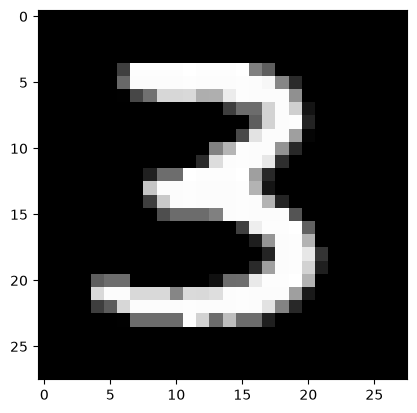

In [10]:
test_predictions(66,W1,b1,W2,b2)

In [11]:
def test_model(X,Y):
    Z1,A1,Z2,A2 = forward_prop(W1,b1,W2,b2,X)
    predictions = get_predictions(A2)
    acc = get_accuracy(predictions,Y)
    print(f"The model has a {acc}% accuracy on the test set")

In [12]:
test_model(X_dev,Y_dev)

[1 0 1 4 0 0 7 3 5 3 8 9 1 3 3 1 8 0 7 6 8 6 2 0 2 3 6 9 9 7 8 9 4 9 6 1 3
 1 1 4 3 1 4 7 2 6 8 7 7 4 7 5 1 9 0 6 2 3 9 1 2 8 7 0 6 3 4 8 1 2 3 9 6 2
 2 4 7 1 4 1 3 4 8 9 2 1 9 8 9 2 8 6 4 6 3 7 1 2 0 5 9 2 7 7 8 8 8 5 0 6 0
 0 2 9 0 4 7 7 1 5 7 9 4 6 1 6 7 6 5 0 4 9 8 8 1 1 7 3 7 8 1 0 3 4 5 4 0 5
 4 5 0 5 1 0 8 3 7 0 9 6 6 9 8 9 8 9 3 8 7 2 4 8 2 4 5 8 8 8 2 6 9 3 1 0 4
 1 5 4 0 6 2 4 7 0 6 0 0 8 3 2 0 0 6 0 0 4 7 2 7 1 9 9 3 9 8 9 1 0 1 3 8 1
 8 7 1 3 7 6 3 6 3 6 3 2 3 6 2 9 9 2 0 2 9 5 4 3 8 2 0 1 9 6 6 3 7 1 1 1 4
 7 0 2 8 2 0 5 6 0 5 9 6 2 0 0 7 2 0 4 2 6 9 1 6 9 3 0 0 2 0 6 8 4 0 2 2 1
 9 5 0 4 8 5 2 9 7 9 2 9 7 4 9 3 6 7 3 6 3 6 8 8 3 7 0 9 2 7 4 0 5 4 6 8 4
 3 3 1 7 8 9 7 6 2 1 7 0 5 6 5 2 9 5 4 6 2 2 2 4 0 7 7 1 2 6 3 4 2 0 5 9 0
 2 1 9 0 6 0 4 5 4 3 1 3 4 2 9 0 7 3 1 5 4 5 3 7 3 8 6 8 4 6 1 1 4 0 0 5 8
 6 7 4 2 8 0 2 5 4 8 3 0 6 4 8 6 4 1 8 1 5 4 7 4 3 2 0 6 0 7 9 2 9 8 9 6 3
 2 4 4 6 4 8 4 1 7 5 8 4 3 9 3 7 3 8 2 2 9 2 8 9 1 9 3 6 0 6 2 4 1 2 7 2 1
 3 4 9 1 8 0 2 3 3 4 1 3 

Now we will test out model on the test data

In [ ]:
test_predictions_all = make_predictions(X_test, W1, b1, W2, b2)
print(test_predictions_all[:20])
# Test set has no labels


[2 0 4 9 2 7 0 3 0 3 5 7 8 0 4 3 3 1 9 0]
